# Problem 6: Market simulation and welfare

Compares the T = 100, J = 3 and T = 100, J = 5 datasets. Notation from the data: `P_opt` prices, `shares`, `x1`, `xi_all` (ξ), `alphas`. Marginal cost is c = 2 + w + Z + eta (γ = (2, 1, 1); only the sum Z + eta matters here). Profits are per unit of market size.

In [1]:
using MAT, DataFrames, Statistics, Random, Plots

d3 = matread("../build/input/public/simulation/100markets3products.mat")
d5 = matread("../build/input/public/simulation/100markets5products.mat")

β = [5.0, 1.0, 1.0]   # true utility coefficients on x = (1, x2, x3)
γ = [2.0, 1.0, 1.0]   # true cost coefficients on (1, w, z)
Base.active_project()

[ Info: Precompiling IJuliaExt [64482eec-cc57-5312-bea1-9f24eb636db7] 

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up


[ Info: Precompiling IJuliaExt [2f4121a4-3b3a-5ce6-9c5e-1f2673ce168a] 

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up


"/home/repo-intro/scripts/julia/Project.toml"

## (a) Prices, markups and profits

In [2]:
function make_df(d)
    p = vec(d["P_opt"])
    c = γ[1] .+ γ[2] .* vec(d["w"]) .+ γ[3] .* vec(d["Z"]) .+ vec(d["eta"])
    DataFrame(price = p, cost = c, markup = p .- c, share = vec(d["shares"]),
              profit = (p .- c) .* vec(d["shares"]))
end

df3, df5 = make_df(d3), make_df(d5);

**J = 3**

In [3]:
describe(df3, :mean, :std, :min, :median, :max)

Row,variable,mean,std,min,median,max
,Symbol,Float64,Float64,Float64,Float64,Float64
1,price,3.02655,1.37116,0.163102,2.82786,7.02848
2,cost,2.05121,1.57761,-2.2592,2.04737,6.28312
3,markup,0.975335,0.483594,0.454138,0.787384,3.23519
4,share,0.224478,0.226342,1.0938e-5,0.14197,0.82444
5,profit,0.30867,0.462638,8.39809e-6,0.105301,2.6537


**J = 5**

In [4]:
describe(df5, :mean, :std, :min, :median, :max)

Row,variable,mean,std,min,median,max
,Symbol,Float64,Float64,Float64,Float64,Float64
1,price,1.89109,1.4349,-1.60735,1.81589,7.54714
2,cost,1.04846,1.63092,-3.49665,1.13128,6.75127
3,markup,0.842627,0.490336,0.310618,0.699243,3.82121
4,share,0.190747,0.243292,5.16551e-6,0.0614537,0.893387
5,profit,0.254205,0.514031,3.93344e-6,0.0407379,3.41382


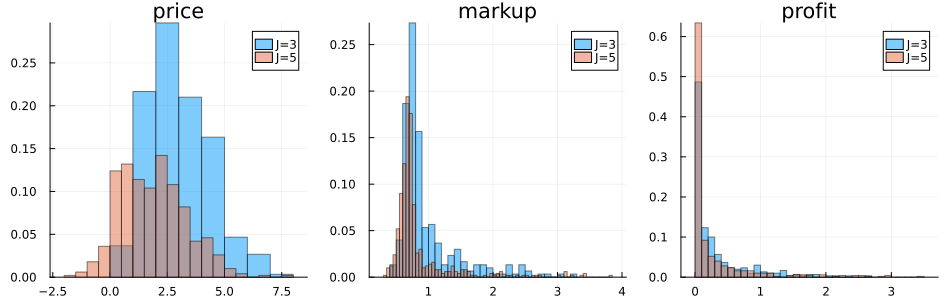

In [5]:
default(size = (950, 300), legend = :topright)
plot(histogram(df3.price, normalize = :probability, alpha = 0.5, label = "J=3", title = "price"),
     histogram(df3.markup, normalize = :probability, alpha = 0.5, label = "J=3", title = "markup"),
     histogram(df3.profit, normalize = :probability, alpha = 0.5, label = "J=3", title = "profit"), layout = (1, 3))
histogram!(df5.price, normalize = :probability, alpha = 0.5, label = "J=5", subplot = 1)
histogram!(df5.markup, normalize = :probability, alpha = 0.5, label = "J=5", subplot = 2)
histogram!(df5.profit, normalize = :probability, alpha = 0.5, label = "J=5", subplot = 3)

## (b) Consumer choices and expected surplus

One common set of consumer draws for both datasets: 1000 consumers per market with α_i = 1 + ν_i, ν_i ~ LN(0,1), and type I extreme value shocks ε. Slot 1 of `ε` is the outside option and slots 2–6 are products 1–5, so the J = 3 dataset uses the first four slots and the J = 5 dataset uses all six. Surplus is in money units: (expected max utility) / α_i, where expected max utility = log(1 + Σ exp(V_j − α_i p_j)) + Euler's constant.

In [6]:
Random.seed!(450)
T, N = 100, 1000
α = 1 .+ exp.(randn(T, N))
ε = -log.(-log.(rand(6, T, N)))

function consumer_surplus(d, α, ε)
    J, T = size(d["shares"])
    N = size(α, 2)
    V = d["x1"] * β .+ vec(d["xi_all"])
    p = vec(d["P_opt"])
    expected = zeros(T, N)
    realized = zeros(T, N)
    choice = zeros(Int, T, N)
    for t in 1:T
        r = (t - 1) * J .+ (1:J)
        u = V[r] .- p[r] * α[t, :]'                    # J x N: utility without ε
        U = vcat(zeros(1, N), u) .+ ε[1:J+1, t, :]     # outside option first
        expected[t, :] = (log.(1 .+ sum(exp.(u), dims = 1))[:] .+ Base.MathConstants.eulergamma) ./ α[t, :]
        realized[t, :] = maximum(U, dims = 1)[:] ./ α[t, :]
        choice[t, :] = map(argmax, eachcol(U)) .- 1    # 0 = outside option
    end
    (expected = expected, realized = realized, choice = choice)
end

cs3 = consumer_surplus(d3, α, ε);
cs5 = consumer_surplus(d5, α, ε);

In [7]:
DataFrame(dataset = ["J=3", "J=5"],
    mean_price = [mean(df3.price), mean(df5.price)],
    mean_markup = [mean(df3.markup), mean(df5.markup)],
    mean_cost = [mean(df3.cost), mean(df5.cost)],
    outside_share = [mean(cs3.choice .== 0), mean(cs5.choice .== 0)],
    expected_CS = [mean(cs3.expected), mean(cs5.expected)],
    realized_CS = [mean(cs3.realized), mean(cs5.realized)],
    sd_consumer_CS = [std(cs3.expected), std(cs5.expected)])

Row,dataset,mean_price,mean_markup,mean_cost,outside_share,expected_CS,realized_CS,sd_consumer_CS
,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,J=3,3.02655,0.975335,2.05121,0.32663,1.6072,1.61121,1.36758
2,J=5,1.89109,0.842627,1.04846,0.04658,3.05677,3.05945,1.70893


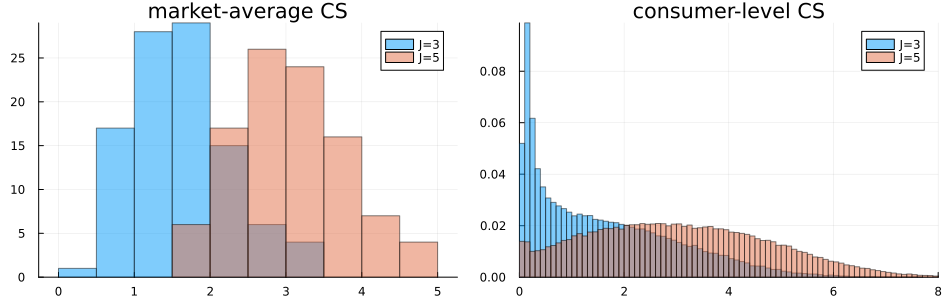

In [8]:
# Distribution of market-average expected surplus across the 100 markets
m3 = vec(mean(cs3.expected, dims = 2))
m5 = vec(mean(cs5.expected, dims = 2))
default(size = (950, 300))
plot(histogram(m3, alpha = 0.5, label = "J=3", title = "market-average CS"),
     histogram(vec(cs3.expected), alpha = 0.5, normalize = :probability, label = "J=3", title = "consumer-level CS", xlims = (0, 8)), layout = (1, 2))
histogram!(m5, alpha = 0.5, label = "J=5", subplot = 1)
histogram!(vec(cs5.expected), alpha = 0.5, normalize = :probability, label = "J=5", subplot = 2)

**Variety only.** Keep the first three products of each J = 5 market at their J = 5 equilibrium prices, so the only change from the J = 5 market is dropping products 4 and 5 (no price adjustment). The difference is the pure variety effect.

In [9]:
keep = mod1.(1:500, 5) .<= 3
d5_first3 = Dict("shares" => d5["shares"][1:3, :], "x1" => d5["x1"][keep, :],
                 "xi_all" => d5["xi_all"][keep], "P_opt" => d5["P_opt"][1:3, :])
cs5_first3 = consumer_surplus(d5_first3, α, ε);

DataFrame(measure = ["CS, J=5 market", "CS, first 3 products at J=5 prices", "variety effect (difference)", "CS, J=3 dataset"],
          expected_CS = [mean(cs5.expected), mean(cs5_first3.expected),
                         mean(cs5.expected) - mean(cs5_first3.expected), mean(cs3.expected)])

Row,measure,expected_CS
,String,Float64
1,"CS, J=5 market",3.05677
2,"CS, first 3 products at J=5 prices",2.75676
3,variety effect (difference),0.300015
4,"CS, J=3 dataset",1.6072


## (c) Do shares sum to one?

Recompute the shares from the model with the true parameters and the supplied `alphas`, including the outside share, and compare with the data.

In [10]:
function model_shares(d)
    J, T = size(d["shares"])
    A = d["alphas"]
    V = d["x1"] * β .+ vec(d["xi_all"])
    p = vec(d["P_opt"])
    inside = zeros(J, T)
    outside = zeros(T)
    for t in 1:T
        r = (t - 1) * J .+ (1:J)
        u = exp.(V[r] .- p[r] * A[t, :]')
        D = 1 .+ sum(u, dims = 1)
        inside[:, t] = mean(u ./ D, dims = 2)
        outside[t] = mean(1 ./ D)
    end
    (inside = inside, outside = outside)
end

m3s, m5s = model_shares(d3), model_shares(d5);

DataFrame(dataset = ["J=3", "J=5"],
    max_abs_sum_minus_1 = [maximum(abs.(vec(sum(m3s.inside, dims = 1)) .+ m3s.outside .- 1)),
                           maximum(abs.(vec(sum(m5s.inside, dims = 1)) .+ m5s.outside .- 1))],
    max_abs_inside_vs_data = [maximum(abs.(m3s.inside .- d3["shares"])), maximum(abs.(m5s.inside .- d5["shares"]))],
    max_abs_outside_vs_data = [maximum(abs.(m3s.outside .- (1 .- vec(sum(d3["shares"], dims = 1))))),
                               maximum(abs.(m5s.outside .- (1 .- vec(sum(d5["shares"], dims = 1)))))],
    min_outside_share = [minimum(m3s.outside), minimum(m5s.outside)])

Row,dataset,max_abs_sum_minus_1,max_abs_inside_vs_data,max_abs_outside_vs_data,min_outside_share
,String,Float64,Float64,Float64,Float64
1,J=3,9.99201e-16,1.11022e-16,1.02696e-15,0.00456653
2,J=5,1.22125e-15,1.66533e-16,1.19284e-15,7.71882e-5


In [11]:
# Monte Carlo check of the simulated choices in (b): outside share by market, simulated vs. model
DataFrame(dataset = ["J=3", "J=5"],
    max_abs_gap = [maximum(abs.(vec(mean(cs3.choice .== 0, dims = 2)) .- m3s.outside)),
                   maximum(abs.(vec(mean(cs5.choice .== 0, dims = 2)) .- m5s.outside))])

Row,dataset,max_abs_gap
,String,Float64
1,J=3,0.0598594
2,J=5,0.0342867


## Summary of results

**(a)** Mean price is 3.03 with J = 3 and 1.89 with J = 5; the mean markup falls only from 0.98 to 0.84 (all markups stay positive, minimum 0.31), while mean marginal cost falls from 2.05 to 1.05. Profit per product is similar (0.31 vs. 0.25) but total profit per market rises with more products (about 0.93 vs. 1.27). The J = 5 prices have a long left tail, including negative prices, because costs are often negative (γ0 = 2 is small relative to the cost noise).

**(b)** Mean consumer surplus is 1.61 with J = 3 and 3.06 with J = 5; realized and expected surplus agree (1.61 / 3.06). The outside share drops from 33% to 4.7%, so almost every consumer buys. Decomposition:
- *Variety*: dropping products 4 and 5 at fixed J = 5 prices lowers surplus by 0.30 (the pure variety effect).
- *Substitution and price adjustment*: more close substitutes lower markups (0.98 to 0.84), but this accounts for at most 0.13 of the 1.14 price gap.
- *The rest* (about 1.15 of the 1.45 gap) comes from the datasets being independent draws, not nested: the J = 5 draws of the firm cost shifter w_j are low (mean cost 1.05 vs. 2.05), so equilibrium prices are much lower for reasons unrelated to competition. The J = 3 vs. J = 5 surplus gap therefore overstates the effect of adding products. A clean answer would hold costs and product characteristics fixed and re-solve the Bertrand equilibrium for each J (not done here).

**(c)** Recomputing shares from the true parameters and the supplied `alphas` reproduces the data to about 1e-15; inside plus outside shares sum to one in every market (maximum deviation 1.2e-15), and the smallest outside share is 8e-5 (J = 5). The simulated choices in (b) match the model's outside shares up to Monte Carlo error (maximum gap 0.06 across 100 markets with 1000 consumers).